In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from PIL import Image
import random
from sklearn.model_selection import train_test_split
from torchvision import datasets, transforms
from math import degrees
from torchvision import transforms
import copy
import torch.nn as nn
import torch.optim as optim
from torchvision import models
import os
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


In [2]:
# Set random seeds for reproducibility
torch.manual_seed(40)

In [ ]:

transform = transforms.Compose([
    transforms.Resize(224),   # ResNet18 works best with 224x224 input
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),  # ImageNet stats
])

dataset = datasets.EuroSAT(root="data", download=True, transform=transform)

print(len(dataset))       # 27000
print(dataset.classes)    # the 10 class names

100%|██████████| 94.3M/94.3M [00:04<00:00, 19.2MB/s]


27000
['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [4]:
# Check for GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [5]:
df = pd.DataFrame(dataset.samples, columns=["path", "label"])
df["class_name"] = df["label"].map(lambda i: dataset.classes[i])

df.to_csv("eurosat_labels.csv", index=False)
print(df.head())

                                               path  label  class_name
0     data\eurosat\2750\AnnualCrop\AnnualCrop_1.jpg      0  AnnualCrop
1    data\eurosat\2750\AnnualCrop\AnnualCrop_10.jpg      0  AnnualCrop
2   data\eurosat\2750\AnnualCrop\AnnualCrop_100.jpg      0  AnnualCrop
3  data\eurosat\2750\AnnualCrop\AnnualCrop_1000.jpg      0  AnnualCrop
4  data\eurosat\2750\AnnualCrop\AnnualCrop_1001.jpg      0  AnnualCrop


In [6]:
df.shape

(27000, 3)

In [7]:
df.head(9)

,path,label,class_name
0,data\eurosat\2750\AnnualCrop\AnnualCrop_1.jpg,0,AnnualCrop
1,data\eurosat\2750\AnnualCrop\AnnualCrop_10.jpg,0,AnnualCrop
2,data\eurosat\2750\AnnualCrop\AnnualCrop_100.jpg,0,AnnualCrop
3,data\eurosat\2750\AnnualCrop\AnnualCrop_1000.jpg,0,AnnualCrop
4,data\eurosat\2750\AnnualCrop\AnnualCrop_1001.jpg,0,AnnualCrop
5,data\eurosat\2750\AnnualCrop\AnnualCrop_1002.jpg,0,AnnualCrop
6,data\eurosat\2750\AnnualCrop\AnnualCrop_1003.jpg,0,AnnualCrop
7,data\eurosat\2750\AnnualCrop\AnnualCrop_1004.jpg,0,AnnualCrop
8,data\eurosat\2750\AnnualCrop\AnnualCrop_1005.jpg,0,AnnualCrop


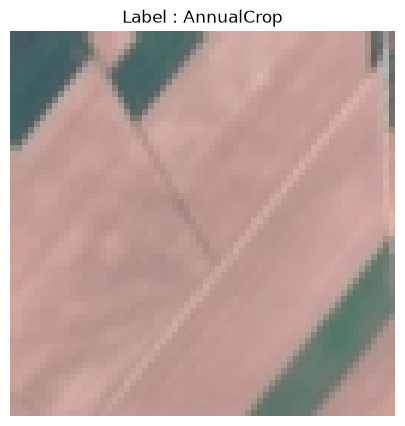

In [12]:
one_img_path=df.iloc[2]['path']
one_img_class_name=df.iloc[2]['class_name']

one_img=Image.open(one_img_path)
plt.figure(figsize=(5,5))
plt.imshow(one_img)
plt.title(f"Label : {one_img_class_name}")
plt.axis('off')
plt.show()

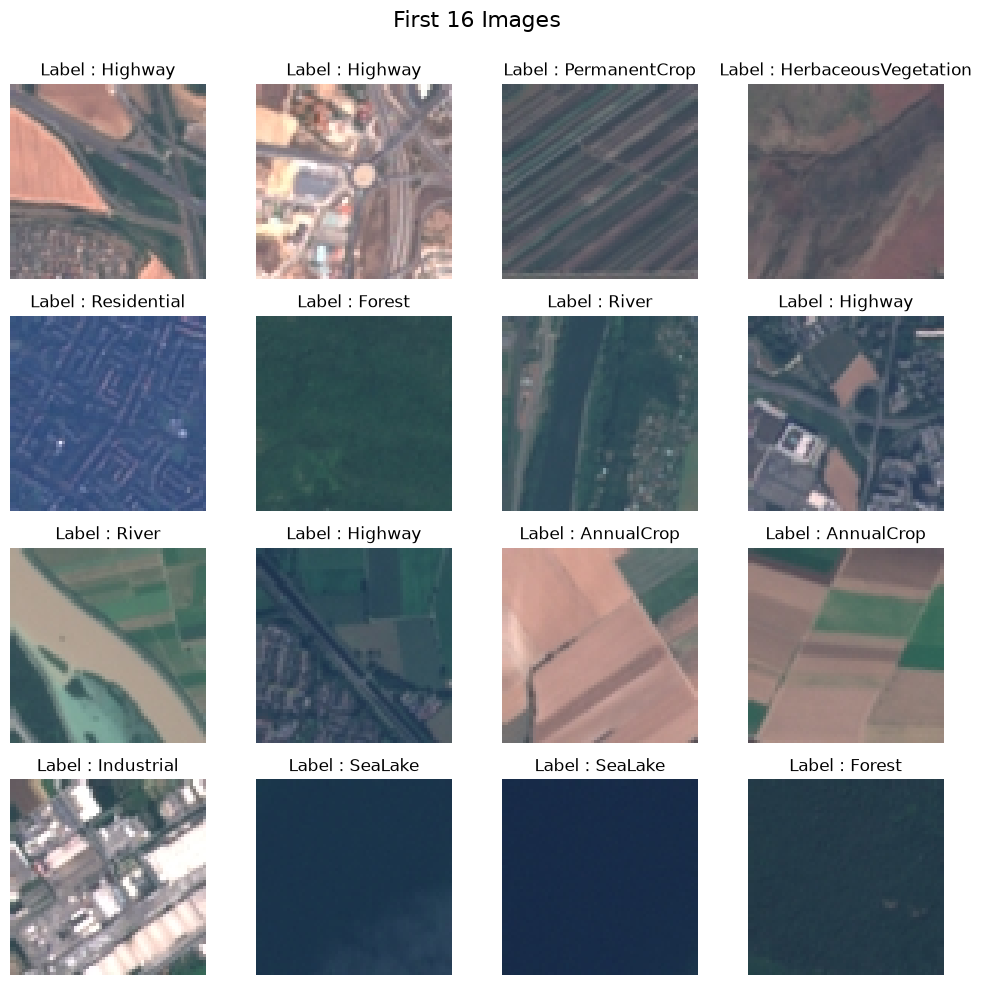

In [15]:
fig,axes=plt.subplots(4,4,figsize=(10,10))
fig.suptitle("First 16 Images",fontsize=16)

for i,ax in enumerate(axes.flat):
  random_number=random.randint(1,27000)
  one_img_path=df.iloc[random_number]['path']
  one_img_class_name=df.iloc[random_number]['class_name']

  one_img=Image.open(one_img_path)
  # plt.figure(figsize=(5,5))
  ax.imshow(one_img)
  ax.set_title(f"Label : {one_img_class_name}")
  ax.axis('off')
plt.tight_layout(rect=[0,0,1,0.98])
plt.show()

#   img=df.iloc[i,2:].values.astype(float).reshape(2,1)
#   ax.imshow(img)
#   ax.axis('off')(f'label:{df.iloc[i,0]}')
# plt.tight_layout(rect=[0,0,1,0.98])
# plt.show()

In [20]:

train_x,temp_x, train_y,temp_y = train_test_split(df['path'],df['label'], test_size=0.30, random_state=42)
val_x, test_x,val_y, test_y = train_test_split(temp_x,temp_y, test_size=0.50, stratify=temp_y, random_state=42)


In [21]:
train_y

9729     3
295      0
24256    9
17938    6
7198     2
        ..
21575    8
5390     1
860      0
15795    5
23654    8
Name: label, Length: 18900, dtype: int64

tensor([[[-0.1137, -0.0667, -0.1137,  ...,  0.4667,  0.4588,  0.4588],
         [-0.1451, -0.0902, -0.1059,  ...,  0.4745,  0.4667,  0.4902],
         [-0.1608, -0.1216, -0.1059,  ...,  0.4980,  0.4745,  0.4902],
         ...,
         [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000]],

        [[ 0.0353,  0.0824,  0.0353,  ...,  0.0431,  0.0353,  0.0353],
         [ 0.0039,  0.0588,  0.0431,  ...,  0.0510,  0.0431,  0.0667],
         [-0.0118,  0.0275,  0.0431,  ...,  0.0588,  0.0510,  0.0667],
         ...,
         [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000],
         [-1.0000, -1.0000, -1.0000,  ..., -1.0000, -1.0000, -1.0000]],

        [[-0.0824, -0.0431, -0.0980,  ..., -0.0039, -0.0118, -0.0275],
         [-0.1137, -0.0510, -0.0902,  ...,  0

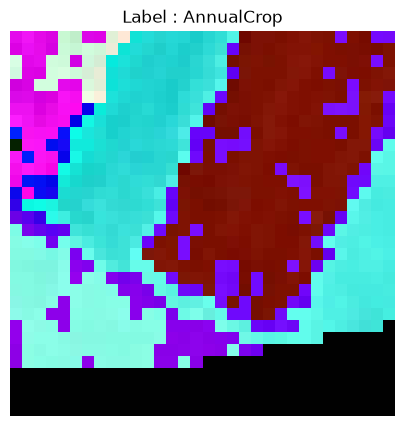

In [ ]:
transform_pipeline=transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2,contrast=0.2),
    transforms.RandomCrop(32,padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])

img_path=df.iloc[7]['path']
raw_img=Image.open(img_path)

augumented_tensor=transform_pipeline(raw_img)
label=img_path=df.iloc[0]['class_name']

print(augumented_tensor)

topil=transforms.ToPILImage()
augumented_tensor_img=topil(augumented_tensor)
# one_img=Image.open(augumented_tensor_img)
plt.figure(figsize=(5,5))
plt.imshow(augumented_tensor_img)
plt.title(f"Label : {label}")
plt.axis('off')
plt.show()

In [23]:
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

transform_pipeline=transforms.Compose([
      transforms.RandomHorizontalFlip(p=0.5),
      transforms.RandomRotation(degrees=15),
      transforms.ColorJitter(brightness=0.2,contrast=0.2),
      # transforms.RandomCrop(32,padding=4),
      transforms.ToTensor(),
      transforms.Normalize(mean,std)
  ])

eval_tf=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean,std)
])


In [24]:
class CustomDataset(Dataset):

  def __init__(self, path, labels,transform):

    # Convert to PyTorch tensors
    self.path = list(path)
    self.labels = list(labels)
    self.transform=transform

  def __len__(self):
    return len(self.path)

  def __getitem__(self, index):
    img= Image.open(self.path[index]).convert("RGB")
    return self.transform(img), int(self.labels[index])

In [25]:
train_dataset = CustomDataset(train_x, train_y,transform_pipeline)
val_dataset= CustomDataset(val_x, val_y,eval_tf)
test_dataset = CustomDataset(test_x, test_y,eval_tf)

In [26]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, pin_memory=True)

In [27]:
class MyNN(nn.Module):
  def __init__(self,input_features):
    super().__init__()
    self.features=nn.Sequential(
        nn.Conv2d(input_features,32,kernel_size=3,padding="same"),
        nn.ReLU(),
        nn.BatchNorm2d(32),
        nn.MaxPool2d(kernel_size=2,stride=2),
        nn.Conv2d(32,64,kernel_size=3,padding="same"),
        nn.BatchNorm2d(64),
        nn.MaxPool2d(kernel_size=2,stride=2)
    )
    self.classifier=nn.Sequential(
        nn.AdaptiveAvgPool2d(1),      # add this line
        nn.Flatten(),
        nn.Linear(64,128),
        nn.ReLU(),
        nn.Dropout(p=0.4),
        nn.Linear(128,10)
    )
  def forward(self,x):
    x=self.features(x)
    x=self.classifier(x)
    return x

In [28]:
learning_rate=0.1
epochs=10

In [29]:
model=MyNN(3)
model.to(device)
criterion=nn.CrossEntropyLoss()
optimizer=optim.SGD(model.parameters(),lr=learning_rate,weight_decay=1e-4)

In [30]:
x, _ = next(iter(train_loader)); print(x.shape)
x, _ = next(iter(val_loader));   print(x.shape)
print(model(x.to(device)).shape)

torch.Size([64, 3, 64, 64])
torch.Size([64, 3, 64, 64])
torch.Size([64, 10])


In [31]:
def validate(model, loader):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss_sum += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / total, correct / total

In [ ]:
def train(model,optimizer,epochs):
  for epoch in range(epochs):
    global best_val_acc, best_weights
    best_val_acc, best_weights = 0.0, None
    model.train()
    total_epoch_loss,correct,total=0.0,0,0
    for batch_features,batch_labels in train_loader:
      batch_features,batch_labels=batch_features.to(device),batch_labels.to(device)
      outputs=model(batch_features)
      loss=criterion(outputs,batch_labels)
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
      total_epoch_loss+=loss.item()*batch_labels.size(0)
      correct+=(outputs.argmax(1)==batch_labels).sum()
      total+=batch_labels.size(0)
    val_loss, val_acc = validate(model, val_loader)
    print(f"Epoch {epoch+1}/{epochs} | "
                f"train loss {total_epoch_loss/total:.3f} acc {correct/total:.3f} | "
                f"val loss {val_loss:.3f} acc {val_acc:.3f}")

    if val_acc > best_val_acc:          # keep the best epoch by validation
              best_val_acc = val_acc
              best_weights = copy.deepcopy(model.state_dict())
best_val_acc, best_weights = 0.0, None
# train(model, optimizer, epochs=10)


In [ ]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 10)   # 10 EuroSAT classes
model = model.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\prath/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:02<00:00, 19.2MB/s]


In [34]:
for p in model.parameters():          # freeze everything
    p.requires_grad = False
for p in model.fc.parameters():       # except the new final layer
    p.requires_grad = True

optimizer = optim.Adam(model.fc.parameters(), lr=1e-3)

best_val_acc, best_weights = 0.0, None
train(model, optimizer, epochs=5)

Epoch 1/5 | train loss 1.027 acc 0.673 | val loss 0.829 acc 0.745
Epoch 2/5 | train loss 0.720 acc 0.767 | val loss 0.744 acc 0.776
Epoch 3/5 | train loss 0.689 acc 0.770 | val loss 0.674 acc 0.789
Epoch 4/5 | train loss 0.661 acc 0.780 | val loss 0.649 acc 0.793
Epoch 5/5 | train loss 0.635 acc 0.789 | val loss 0.639 acc 0.797


In [35]:
model.load_state_dict(best_weights)   # start from the best stage 1 result

for p in model.layer4.parameters():   # unfreeze the last residual block
    p.requires_grad = True

optimizer = optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-4},   # pretrained layers: small lr
    {"params": model.fc.parameters(),     "lr": 1e-4},
])

train(model, optimizer, epochs=10)

Epoch 1/10 | train loss 0.466 acc 0.846 | val loss 0.457 acc 0.871
Epoch 2/10 | train loss 0.327 acc 0.890 | val loss 0.284 acc 0.905
Epoch 3/10 | train loss 0.266 acc 0.911 | val loss 0.279 acc 0.912
Epoch 4/10 | train loss 0.236 acc 0.918 | val loss 0.325 acc 0.877
Epoch 5/10 | train loss 0.203 acc 0.931 | val loss 0.221 acc 0.927
Epoch 6/10 | train loss 0.194 acc 0.934 | val loss 0.204 acc 0.927
Epoch 7/10 | train loss 0.174 acc 0.939 | val loss 0.202 acc 0.931
Epoch 8/10 | train loss 0.163 acc 0.943 | val loss 0.259 acc 0.915
Epoch 9/10 | train loss 0.151 acc 0.947 | val loss 0.202 acc 0.933
Epoch 10/10 | train loss 0.138 acc 0.951 | val loss 0.207 acc 0.932


In [36]:
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable: {trainable:,} of {total:,}")

Trainable: 8,398,858 of 11,181,642


In [ ]:

def test(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            preds = model(images).argmax(1).cpu()
            all_preds.append(preds)
            all_labels.append(labels)
    return torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()

model.load_state_dict(best_weights)         # best epoch chosen by validation
preds, labels = test(model, test_loader)

print(f"Test accuracy: {(preds == labels).mean():.4f}")
print(classification_report(labels, preds, digits=3))
print("-"*100)
print(confusion_matrix(labels, preds))

Test accuracy: 0.9336
              precision    recall  f1-score   support

           0      0.952     0.943     0.947       439
           1      0.934     0.973     0.953       449
           2      0.949     0.839     0.891       461
           3      0.879     0.867     0.873       384
           4      0.973     0.970     0.972       371
           5      0.909     0.877     0.893       309
           6      0.866     0.943     0.903       369
           7      0.981     0.981     0.981       462
           8      0.889     0.943     0.915       367
           9      0.984     0.984     0.984       439

    accuracy                          0.934      4050
   macro avg      0.931     0.932     0.931      4050
weighted avg      0.934     0.934     0.933      4050

----------------------------------------------------------------------------------------------------
[[414   1   1   6   0   3   8   0   5   1]
 [  0 437   2   0   0   4   0   1   0   5]
 [  1  22 387   5   0  15  26   

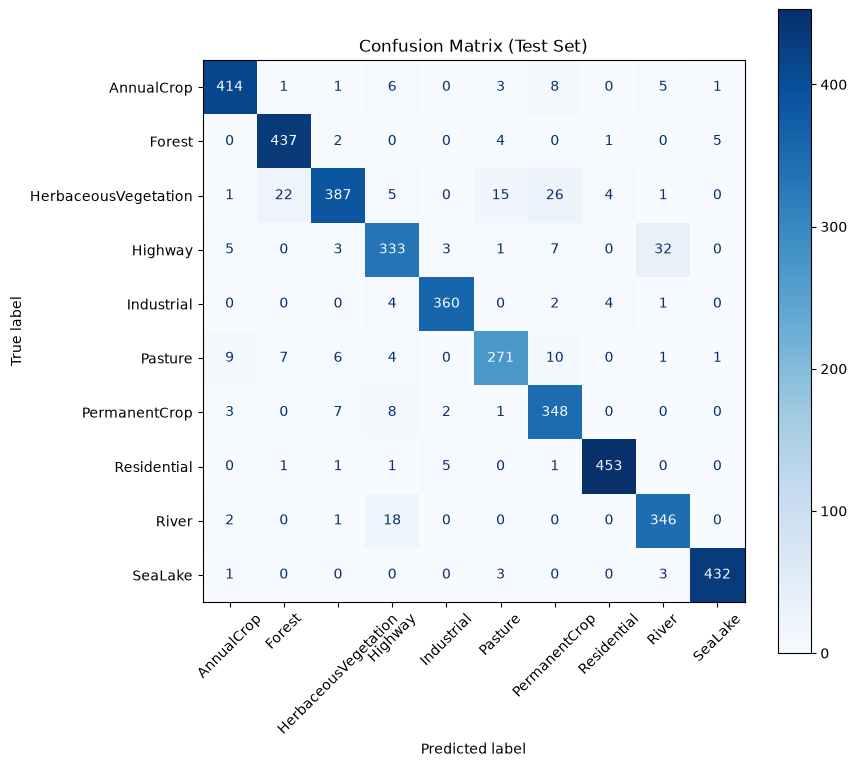

In [ ]:

os.makedirs("images", exist_ok=True)

classes = ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial',
           'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(
    labels, preds, display_labels=classes,
    xticks_rotation=45, cmap="Blues", ax=ax
)
plt.title("Confusion Matrix (Test Set)")
plt.tight_layout()
plt.savefig("images/confusion_matrix.png", dpi=150)
plt.show()

In [ ]:

classes=['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
cm = confusion_matrix(labels, preds)

pairs = []
for i in range(10):
    for j in range(10):
        if i != j and cm[i, j] > 0:
            pairs.append((cm[i, j], labels[i], labels[j]))

pairs.sort(reverse=True)
for n, true_c, pred_c in pairs[:5]:
    print(f"{n} images: true {classes[true_c]} -> predicted {classes[pred_c]}")

32 images: true Highway -> predicted SeaLake
26 images: true SeaLake -> predicted SeaLake
22 images: true SeaLake -> predicted Pasture
18 images: true SeaLake -> predicted Highway
15 images: true SeaLake -> predicted HerbaceousVegetation


269 wrong out of 4050


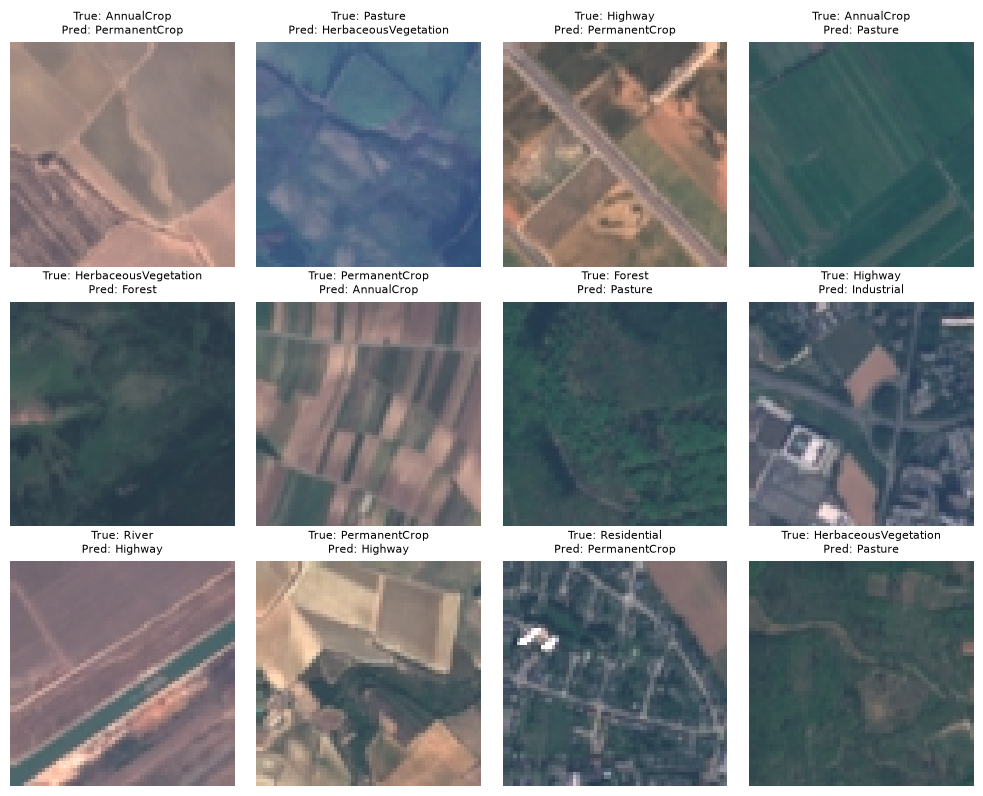

In [ ]:

wrong = np.where(preds != labels)[0]          # positions of the mistakes
print(f"{len(wrong)} wrong out of {len(labels)}")

sample = np.random.choice(wrong, size=min(12, len(wrong)), replace=False)
paths = list(test_x)                           # same order as test_loader (shuffle=False)

fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for ax in axes.flat:
    ax.axis("off")
for ax, idx in zip(axes.flat, sample):
    ax.imshow(Image.open(paths[idx]).convert("RGB"))
    ax.set_title(f"True: {classes[labels[idx]]}\nPred: {classes[preds[idx]]}", fontsize=8)
plt.tight_layout()
plt.savefig("images/misclassified_examples.png", dpi=150)   # new line
plt.show()

In [40]:
a, b = classes.index("PermanentCrop"), classes.index("AnnualCrop")
idx_pair = np.where((labels == a) & (preds == b))[0]
idx_pair


array([ 474, 1220, 2329])